# 3_inferencia - probabilidades por data na área de estudo

Aplica cada classificador às seis imagens da área de estudo (Belterra, órbita-ponto 227/062, 2005–2010) e grava, para cada classificador e ano, um GeoTIFF com **uma banda por classe** contendo a **log-probabilidade** da classe (classes equiprováveis). É a entrada do CMAP (`4_cmap`). O nome da classe fica na descrição da banda.

**Modelos.** São usados os 5 modelos da repetição `REPETICAO`, um por fold, cada um treinado com 3/5 das órbitas-ponto do Pará. A probabilidade final de cada pixel é a **média das probabilidades** dos 5 modelos. A área de estudo não está em nenhum fold, então não há produto "fora do fold": a cena inteira serve para classificar e para a avaliação.
- **CNN:** carregada dos arquivos `modelo_rR_fF.pt` do experimento escolhido, com a temperatura gravada.
- **MaxVer, RF e RF com contexto:** os modelos não foram gravados no `1_baselines`, então são refeitos aqui com os parâmetros de `config_baselines.json` e as mesmas sementes. O RF com contexto usa a janela igual ao patch da CNN.
- Em cada fold, as probabilidades do teste calculadas aqui são **conferidas** com as gravadas pelo `1_baselines` e pelo `2_treino_cnn`.

**Versão bruta ou calibrada.** Na etapa 1, a calibração ajudou o MaxVer e o RF, mas não o RF com contexto, e na CNN é quase neutra. Com `VERSAO = "automatica"`, cada classificador usa a versão com a menor NLL média no teste dos folds do Pará (seção 1). A escolha usa só os folds do Pará; a área de estudo continua independente.

**Escala e máscara.** As imagens são levadas à escala fixa do 0b (`escala_fixa.json`). Um pixel só recebe probabilidade numa data se a janela inteira em volta dele (o patch da CNN) estiver dentro da grade e sem pixel inválido; a mesma máscara vale para **todos** os classificadores (`mascara_inferencia_AAAA.tif`).

**Conferências.** (i) Teste dos folds × probabilidades gravadas; (ii) domínio: valores de cada classe do TerraClass na área de estudo × treino; (iii) classe mais provável de cada data × TerraClass 2008 e 2010, antes do CMAP.

Lê `C:\cmap_ftl\dados_preparados\imagens\` (só leitura) e as saídas do 0b, 0c, 1_baselines e 2_treino_cnn; grava só em `resultados\3_inferencia\<NOME_INFERENCIA>\`.


Obs.: Documentação do Código feita com auxílio de IA (Claude Opus 5.5)

## Parâmetros

In [1]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO         = r"C:\cmap_ftl\terraclass"
PASTA_IMAGENS         = r"C:\cmap_ftl\dados_preparados\imagens"     # só leitura: landsat_AAAA.tif e mascara_AAAA.tif
NOME_CONJUNTO         = "6bandas"
PASTA_CONJUNTO        = rf"{PASTA_PROJETO}\resultados\0b_conjunto_treino\{NOME_CONJUNTO}"
EXPERIMENTO_BASELINES = "6bandas_experimento_inicial"
PASTA_BASELINES       = rf"{PASTA_PROJETO}\resultados\1_baselines\{EXPERIMENTO_BASELINES}"
EXPERIMENTO_CNN       = "patch5"                                    # experimento escolhido no 2_treino_cnn
PASTA_CNN             = rf"{PASTA_PROJETO}\resultados\2_treino_cnn\{EXPERIMENTO_CNN}"
PASTA_REFERENCIA      = rf"{PASTA_PROJETO}\resultados\0c_referencia_terraclass"
NOME_INFERENCIA       = "6bandas_patch5"                            # um nome por combinação de experimentos
PASTA_SAIDA           = rf"{PASTA_PROJETO}\resultados\3_inferencia\{NOME_INFERENCIA}"

ANOS = [2005, 2006, 2007, 2008, 2009, 2010]
CLASSIFICADORES = ["MaxVer", "RF", "RF_contexto", "CNN"]   # o RF com contexto usa a janela do patch da CNN
REPETICAO = 0                     # os 5 modelos (folds) desta repetição são combinados pela média
VERSAO = "automatica"             # ou um dicionário, ex.: {"MaxVer": "calibrado", "RF": "calibrado", "RF_contexto": "bruto", "CNN": "bruto"}

TOLERANCIA_CONFERENCIA = 1e-4     # diferença máxima aceita nas probabilidades do teste
LOTE = 65536                      # pixels por lote
N_THREADS = None                  # None = todos os núcleos (PyTorch)

## 1. Conjunto, modelos e versão de cada classificador

Lê a legenda e a escala do 0b, os parâmetros dos baselines (`config_baselines.json`) e a configuração da CNN, e confere se são compatíveis (mesmas classes, mesmo conjunto, janela do RF com contexto igual ao patch da CNN). Em seguida, escolhe a versão (bruta ou calibrada) de cada classificador.

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import rasterio
import torch
from torch import nn
from scipy import ndimage
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

if not os.path.abspath(PASTA_SAIDA).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
    raise ValueError(f"PASTA_SAIDA precisa ficar dentro de {PASTA_PROJETO}")
os.makedirs(PASTA_SAIDA, exist_ok=True)
if N_THREADS:
    torch.set_num_threads(N_THREADS)

# ---- legenda e escala fixa do 0b
with open(os.path.join(PASTA_CONJUNTO, "legenda.json"), encoding="utf-8") as arq:
    legenda = json.load(arq)
with open(os.path.join(PASTA_CONJUNTO, "escala_fixa.json"), encoding="utf-8") as arq:
    escala = json.load(arq)
CLASSES = {int(k): v for k, v in legenda["classes"].items()}
CODIGOS = sorted(CLASSES)
SIGLAS = [CLASSES[c] for c in CODIGOS]
K = len(CODIGOS)
BANDAS = legenda["bandas"]                       # ordem das bandas nos patches e nas imagens padronizadas
if escala["bandas"] != BANDAS:
    raise ValueError("A escala fixa e a legenda do 0b têm bandas diferentes")

# ---- baselines: parâmetros do 1_baselines
with open(os.path.join(PASTA_BASELINES, "config_baselines.json"), encoding="utf-8") as arq:
    cfg_base = json.load(arq)
if cfg_base["conjunto"] != NOME_CONJUNTO:
    raise ValueError(f"Os baselines usaram o conjunto {cfg_base['conjunto']}, não {NOME_CONJUNTO}")
ib_base = [BANDAS.index(b) for b in cfg_base["bandas"]]

# ---- CNN: configuração gravada nos modelos
arq_cnn0 = os.path.join(PASTA_CNN, f"modelo_r{REPETICAO}_f0.pt")
ck0 = torch.load(arq_cnn0, weights_only=True)
if list(ck0["classes"]) != SIGLAS or ck0["conjunto"] != NOME_CONJUNTO:
    raise ValueError(f"CNN treinada com classes {ck0['classes']} / conjunto {ck0['conjunto']}")
TAM_CNN = int(ck0["tamanho_patch"])
ib_cnn = [BANDAS.index(b) for b in ck0["bandas"]]
NOME_CTX = f"RF_contexto_{TAM_CNN}x{TAM_CNN}"
if "RF_contexto" in CLASSIFICADORES and TAM_CNN not in cfg_base["janelas_contexto"]:
    raise ValueError(f"O 1_baselines não tem a janela {TAM_CNN}x{TAM_CNN} ({cfg_base['janelas_contexto']})")
NOMES_SAIDA = {"MaxVer": "MaxVer", "RF": "RF", "RF_contexto": NOME_CTX, "CNN": "CNN"}
JANELA = TAM_CNN                                  # janela que precisa estar inteira e válida (CNN e RF com contexto)
MEIO = JANELA // 2

# ---- patches e metadados (refazer os baselines e conferir os testes)
X9 = np.load(os.path.join(PASTA_CONJUNTO, "patches_9x9.npy"), mmap_mode="r")
meta = pd.read_csv(os.path.join(PASTA_CONJUNTO, "metadados_patches.csv"))
y_todos = np.searchsorted(CODIGOS, meta["classe"].to_numpy())
N_FOLDS = int(meta["fold_r0"].max()) + 1
c9 = X9.shape[-1] // 2
mc = TAM_CNN // 2
centro_p = np.asarray(X9[:, ib_base, c9, c9], dtype=np.float64)
janela_p = np.asarray(X9[:, ib_base, c9 - mc:c9 + mc + 1, c9 - mc:c9 + mc + 1], dtype=np.float64)
contexto_p = np.concatenate([centro_p, janela_p.mean(axis=(2, 3)), janela_p.std(axis=(2, 3))], axis=1)
del janela_p

# ---- versão de cada classificador
if VERSAO == "automatica":
    tabs = [pd.read_csv(os.path.join(PASTA_BASELINES, "resultados_baselines.csv")),
            pd.read_csv(os.path.join(PASTA_CNN, "resultados_cnn.csv"))]
    res = pd.concat(tabs, ignore_index=True)
    nll = res.groupby(["classificador", "versao"])["nll_balanceado"].mean().unstack()
    versao_de, linhas = {}, []
    for nome in CLASSIFICADORES:
        n_s = NOMES_SAIDA[nome]
        versao_de[nome] = "calibrado" if nll.loc[n_s, "calibrado"] < nll.loc[n_s, "bruto"] else "bruto"
        linhas.append({"classificador": n_s, "nll_bruto": nll.loc[n_s, "bruto"], "nll_calibrado": nll.loc[n_s, "calibrado"],
                       "versao_usada": versao_de[nome]})
    tab_versao = pd.DataFrame(linhas)
else:
    versao_de = dict(VERSAO)
    tab_versao = pd.DataFrame([{"classificador": NOMES_SAIDA[n], "versao_usada": versao_de[n]} for n in CLASSIFICADORES])
tab_versao.to_csv(os.path.join(PASTA_SAIDA, "versao_classificadores.csv"), index=False)
print(f"{len(meta)} patches | classes {SIGLAS} | bandas {BANDAS} | repetição {REPETICAO} ({N_FOLDS} modelos por classificador)")
print(f"CNN: experimento {EXPERIMENTO_CNN}, patch {TAM_CNN}x{TAM_CNN}, bandas {ck0['bandas']} | baselines: {EXPERIMENTO_BASELINES}, bandas {cfg_base['bandas']}")
print("\nVersão de cada classificador (NLL média no teste dos folds do Pará):")
print(tab_versao.round(3).to_string(index=False))

100643 patches | classes ['F', 'VS', 'PA', 'AG'] | bandas ['B1', 'B2', 'B3', 'B4', 'B5', 'B7'] | repetição 0 (5 modelos por classificador)
CNN: experimento patch5, patch 5x5, bandas ['B1', 'B2', 'B3', 'B4', 'B5', 'B7'] | baselines: 6bandas_experimento_inicial, bandas ['B1', 'B2', 'B3', 'B4', 'B5', 'B7']

Versão de cada classificador (NLL média no teste dos folds do Pará):
  classificador  nll_bruto  nll_calibrado versao_usada
         MaxVer      1.223          1.021    calibrado
             RF      1.035          1.012    calibrado
RF_contexto_5x5      0.878          0.889        bruto
            CNN      0.755          0.758        bruto


## 2. Imagens na escala fixa e máscara comum

Cada banda é convertida para a escala fixa do 0b: z = (ρ − média) / desvio, com as estatísticas de `escala_fixa.json`. As imagens de `dados_preparados` já estão em reflectância de superfície (o 0a conferiu que coincidem com o produto do GEE). Pixels marcados na máscara de qualidade ou sem valor ficam inválidos, e só recebem probabilidade os pixels cuja janela `JANELA` × `JANELA` está inteira e válida.

In [3]:
imagens_z, valida_janela = {}, {}
grade = None
for ano in ANOS:
    with rasterio.open(os.path.join(PASTA_IMAGENS, f"landsat_{ano}.tif")) as src:
        if grade is None:
            grade = {"crs": src.crs, "transform": src.transform, "height": src.height, "width": src.width}
        elif (src.crs, src.transform, src.height, src.width) != (grade["crs"], grade["transform"], grade["height"], grade["width"]):
            raise ValueError(f"landsat_{ano}.tif não está na mesma grade das outras datas")
        descricoes = list(src.descriptions)
        faltam = [b for b in BANDAS if b not in descricoes]
        if faltam:
            raise ValueError(f"landsat_{ano}.tif não tem as bandas {faltam} (tem {descricoes})")
        img = src.read([descricoes.index(b) + 1 for b in BANDAS]).astype(np.float64)
    with rasterio.open(os.path.join(PASTA_IMAGENS, f"mascara_{ano}.tif")) as src:
        mascara = src.read(1)
    valida = (mascara == 0) & np.all(np.isfinite(img), axis=0)
    z = np.empty(img.shape, dtype=np.float32)
    for b, banda in enumerate(BANDAS):
        est = escala["estatisticas"][banda]
        z[b] = (img[b] - est["media"]) / est["desvio"]
    z[:, ~valida] = np.nan
    imagens_z[ano] = z
    valida_janela[ano] = ndimage.minimum_filter(valida.astype(np.uint8), size=JANELA, mode="constant", cval=0) == 1
    perfil_m = {"driver": "GTiff", "dtype": "uint8", "count": 1, "nodata": None, "compress": "deflate", **grade}
    with rasterio.open(os.path.join(PASTA_SAIDA, f"mascara_inferencia_{ano}.tif"), "w", **perfil_m) as dst:
        dst.write((~valida_janela[ano]).astype(np.uint8), 1)
        dst.set_band_description(1, "sem_probabilidade")
    print(f"{ano}: pixels sem probabilidade {int((~valida_janela[ano]).sum())} "
          f"({100 * (~valida_janela[ano]).mean():.2f}% da grade, incluindo a margem de {MEIO} px)")
H, W = grade["height"], grade["width"]

2005: pixels sem probabilidade 7963 (0.88% da grade, incluindo a margem de 2 px)
2006: pixels sem probabilidade 11510 (1.28% da grade, incluindo a margem de 2 px)
2007: pixels sem probabilidade 8483 (0.94% da grade, incluindo a margem de 2 px)
2008: pixels sem probabilidade 8904 (0.99% da grade, incluindo a margem de 2 px)
2009: pixels sem probabilidade 7920 (0.88% da grade, incluindo a margem de 2 px)
2010: pixels sem probabilidade 8007 (0.89% da grade, incluindo a margem de 2 px)


## 3. Conferência de domínio

Compara, para cada classe do TerraClass (2008 e 2010), a mediana de cada banda (unidades z) nos pixels da área de estudo sem outro rótulo na janela 9 × 9 com a mediana dos patches de treino do mesmo ano e mesma condição. Diferenças pequenas (até cerca de 0,3) indicam que a classe na área de estudo se parece com a média do Pará; diferenças grandes indicam que os classificadores vão encontrar, nesta classe, valores pouco representados no treino. É um diagnóstico: nada é alterado aqui.

In [4]:
linhas = []
anos_m, dist_m = meta["ano"].to_numpy(), meta["dist_borda_px"].to_numpy()
centro_todas = np.asarray(X9[:, :, c9, c9], dtype=np.float64)
for ano in ANOS:
    arq_ref = os.path.join(PASTA_REFERENCIA, f"referencia_{ano}.tif")
    if not os.path.exists(arq_ref):
        continue
    with rasterio.open(arq_ref) as src:
        ref = src.read(1)
        if src.transform != grade["transform"] or ref.shape != (H, W):
            raise ValueError(f"{arq_ref} não está na grade das imagens")
    with rasterio.open(os.path.join(PASTA_REFERENCIA, f"dist_borda_{ano}.tif")) as src:
        dist_ref = src.read(1)
    for k, cod in enumerate(CODIGOS):
        m_area = (ref == cod) & (dist_ref == 5) & np.all(np.isfinite(imagens_z[ano]), axis=0)
        m_treino = (y_todos == k) & (dist_m == 5) & (anos_m == ano)
        if m_area.sum() < 30 or m_treino.sum() < 30:
            continue
        med_area = np.median(imagens_z[ano][:, m_area], axis=1)
        med_treino = np.median(centro_todas[m_treino], axis=0)
        for b, banda in enumerate(BANDAS):
            linhas.append({"ano": ano, "classe": SIGLAS[k], "banda": banda, "n_area": int(m_area.sum()),
                           "mediana_area": med_area[b], "mediana_treino": med_treino[b], "diferenca": med_area[b] - med_treino[b]})
del centro_todas
tab_dominio = pd.DataFrame(linhas)
if len(tab_dominio):
    tab_dominio.to_csv(os.path.join(PASTA_SAIDA, "conferencia_dominio.csv"), index=False)
    print("Diferença das medianas (área de estudo − treino), em unidades z:")
    print(tab_dominio.pivot_table(index=["ano", "classe"], columns="banda", values="diferenca")[BANDAS]
          .reindex(SIGLAS, level="classe").round(2).to_string())
else:
    print("Referência do 0c não encontrada: conferência de domínio não calculada")

Diferença das medianas (área de estudo − treino), em unidades z:
banda          B1    B2    B3    B4    B5    B7
ano  classe                                    
2008 F       0.04 -0.07 -0.05 -0.04  0.12  0.02
     VS     -0.04 -0.20 -0.07  0.03  0.10 -0.02
     PA     -0.17 -0.06 -0.38  0.87 -0.12 -0.30
     AG     -1.15 -0.95 -1.11  0.29 -0.76 -1.06
2010 F       0.02 -0.04 -0.00 -0.03  0.08  0.03
     VS     -0.12 -0.13 -0.16  0.10  0.04 -0.05
     PA     -0.43 -0.11 -0.64  1.19 -0.35 -0.55
     AG     -1.57 -1.25 -1.62  0.65 -0.57 -1.08


## 4. Probabilidades

Para cada classificador e cada fold *f* da repetição:

1. Obtém o modelo da divisão: carrega a CNN ou refaz o baseline com o treino dessa divisão (teste = fold *f*, validação = fold *f* + 1).
2. Baselines: prevê a validação e ajusta a temperatura (mesmo procedimento do `1_baselines`). CNN: usa a temperatura gravada.
3. Prevê o teste e confere com as probabilidades gravadas.
4. Prevê todos os pixels válidos de cada data e acumula.

No fim, a probabilidade de cada pixel é a média das probabilidades dos 5 modelos, calculada em escala logarítmica.

In [5]:
perfil_p = {"driver": "GTiff", "dtype": "float32", "nodata": np.nan, "compress": "deflate", "predictor": 3,
            "tiled": True, "blockxsize": 256, "blockysize": 256, **grade}
r = REPETICAO
temperaturas, conferencia, mapas = [], [], {}
inicio = time.time()
for nome in CLASSIFICADORES:
    nome_saida, versao = NOMES_SAIDA[nome], versao_de[nome]
    soma_log = {ano: np.full((K, H, W), -np.inf, dtype=np.float32) for ano in ANOS}
    for f in range(N_FOLDS):
        t_div = time.time()
        modelo = None                                   # libera o modelo anterior
        fv = (f + 1) % N_FOLDS
        fold = meta[f"fold_r{r}"].to_numpy()
        m_te, m_va = fold == f, fold == fv
        m_tr = ~(m_te | m_va)

        # ---------------- 1. modelo da divisão (r, f)
        if nome == "CNN":
            ck = torch.load(os.path.join(PASTA_CNN, f"modelo_r{r}_f{f}.pt"), weights_only=True)
            F1, F2 = ck["filtros"]
            modelo = nn.Sequential(
                nn.Conv2d(ck["n_bandas"], F1, kernel_size=3, padding=1), nn.BatchNorm2d(F1), nn.ReLU(),
                nn.Conv2d(F1, F2, kernel_size=3, padding=1), nn.BatchNorm2d(F2), nn.ReLU(),
                nn.Flatten(), nn.Dropout(ck["dropout"]), nn.Linear(F2 * TAM_CNN * TAM_CNN, K))
            modelo.load_state_dict(ck["estado"])
            modelo.eval()
            T_fold = float(ck["temperatura"])
        elif nome == "MaxVer":
            parametros = []
            for k in range(K):
                Xk = centro_p[m_tr & (y_todos == k)]
                cov = np.cov(Xk, rowvar=False) + cfg_base["ridge"] * np.eye(Xk.shape[1])
                parametros.append((Xk.mean(axis=0), np.linalg.inv(cov), np.linalg.slogdet(cov)[1]))
        else:
            atrib_p = centro_p if nome == "RF" else contexto_p
            modelo = RandomForestClassifier(n_estimators=cfg_base["rf_n_arvores"], class_weight="balanced", n_jobs=-1,
                                            random_state=cfg_base["rf_semente"] + 100 * r + f)
            modelo.fit(atrib_p[m_tr], y_todos[m_tr])

        # ---------------- 2. previsões: validação (baselines), teste e pixels de cada data
        tarefas = ([] if nome == "CNN" else [("validacao", None, np.nonzero(m_va)[0])]) + [("teste", None, np.nonzero(m_te)[0])]
        tarefas += [("cena", ano, np.flatnonzero(valida_janela[ano])) for ano in ANOS]
        for tipo, ano, idx in tarefas:
            if tipo == "cena":
                V = sliding_window_view(imagens_z[ano], (JANELA, JANELA), axis=(1, 2))
                lin_x, col_x = np.divmod(idx, W)
            lp = np.empty((len(idx), K))
            for i in range(0, len(idx), LOTE):
                # janelas JANELA x JANELA do lote, (n, bandas, JANELA, JANELA), todas as bandas do conjunto
                if tipo == "cena":
                    J = V[:, lin_x[i:i + LOTE] - MEIO, col_x[i:i + LOTE] - MEIO].transpose(1, 0, 2, 3)
                else:
                    J = X9[idx[i:i + LOTE]][:, :, c9 - MEIO:c9 + MEIO + 1, c9 - MEIO:c9 + MEIO + 1]
                J = np.ascontiguousarray(J, dtype=np.float32)
                if nome == "CNN":
                    xb = torch.from_numpy(np.ascontiguousarray(J[:, ib_cnn]))
                    with torch.no_grad():
                        s = modelo(xb).numpy().astype(np.float64)
                elif nome == "MaxVer":
                    x = J[:, ib_base, MEIO, MEIO].astype(np.float64)
                    s = np.empty((len(J), K))
                    for k, (mu, cov_inv, logdet) in enumerate(parametros):
                        d = x - mu
                        s[:, k] = -0.5 * (np.einsum("ij,jk,ik->i", d, cov_inv, d) + logdet + d.shape[1] * np.log(2 * np.pi))
                else:
                    x = J[:, ib_base, MEIO, MEIO].astype(np.float64)
                    if nome == "RF_contexto":
                        jan = J[:, ib_base, MEIO - mc:MEIO + mc + 1, MEIO - mc:MEIO + mc + 1].astype(np.float64)
                        x = np.concatenate([x, jan.mean(axis=(2, 3)), jan.std(axis=(2, 3))], axis=1)
                    Pr = np.zeros((len(J), K))
                    Pr[:, modelo.classes_] = modelo.predict_proba(x)
                    Pr = np.clip(Pr, cfg_base["eps_rf"], None)
                    s = np.log(Pr / Pr.sum(axis=1, keepdims=True))
                mx = s.max(axis=1, keepdims=True)
                lp[i:i + len(J)] = s - (mx + np.log(np.exp(s - mx).sum(axis=1, keepdims=True)))

            if tipo == "validacao":
                y_val = y_todos[idx]
                cont = np.bincount(y_val, minlength=K)
                pesos_val = len(y_val) / (np.count_nonzero(cont) * cont[y_val])
                logp_val = lp
                # ---- temperature scaling: busca em grade do T que minimiza o NLL balanceado na validação
                melhor_T, melhor_nll = 1.0, np.inf
                idx_val = np.arange(len(y_val))
                for T in np.exp(np.linspace(np.log(0.05), np.log(20.0), 300)):
                    z = logp_val / T
                    z = z - z.max(axis=1, keepdims=True)
                    lse = np.log(np.exp(z).sum(axis=1))
                    nll_T = -(pesos_val * (z[idx_val, y_val] - lse)).sum() / pesos_val.sum()
                    if nll_T < melhor_nll:
                        melhor_T, melhor_nll = float(T), float(nll_T)
                T_fold = melhor_T
                continue

            T_usado = T_fold if versao == "calibrado" else 1.0
            z = lp / T_usado
            z = z - z.max(axis=1, keepdims=True)
            logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))

            if tipo == "teste":
                if nome == "CNN":
                    arq, chave = os.path.join(PASTA_CNN, f"probs_cnn_r{r}_f{f}.npz"), f"logp_CNN_{versao}"
                else:
                    arq, chave = os.path.join(PASTA_BASELINES, f"probs_baselines_r{r}_f{f}.npz"), f"logp_{nome_saida}_{versao}"
                dif = np.nan
                if os.path.exists(arq):
                    with np.load(arq) as gravado:
                        if chave in gravado.files and np.array_equal(gravado["id_teste"], meta["id"].to_numpy()[idx]):
                            dif = float(np.abs(np.exp(logp) - np.exp(gravado[chave].astype(np.float64))).max())
                conferencia.append({"classificador": nome_saida, "repeticao": r, "fold": f, "versao": versao,
                                    "dif_max_prob": dif, "ok": bool(dif <= TOLERANCIA_CONFERENCIA)})
                if not dif <= TOLERANCIA_CONFERENCIA:
                    print(f"   ATENÇÃO {nome_saida} f={f}: teste não confere com o arquivo gravado (dif. = {dif})")
            else:
                g = np.full((K, H * W), np.nan, dtype=np.float32)
                g[:, idx] = logp.T
                with np.errstate(invalid="ignore"):          # pixels sem probabilidade (NaN) continuam NaN
                    soma_log[ano] = np.logaddexp(soma_log[ano], g.reshape(K, H, W))
        temperaturas.append({"classificador": nome_saida, "repeticao": r, "fold": f, "T": T_fold, "versao_usada": versao})
        print(f"{nome_saida} f={f}: T = {T_fold:.2f} ({versao}), conferência {conferencia[-1]['dif_max_prob']:.1e} "
              f"({time.time() - t_div:.0f} s)")

    # ---------------- 3. média dos 5 modelos e gravação
    mapas[nome_saida] = {}
    os.makedirs(os.path.join(PASTA_SAIDA, nome_saida), exist_ok=True)
    for ano in ANOS:
        g = soma_log[ano] - np.log(N_FOLDS)
        with rasterio.open(os.path.join(PASTA_SAIDA, nome_saida, f"logp_{ano}.tif"), "w", count=K, **perfil_p) as dst:
            dst.write(g)
            for b in range(K):
                dst.set_band_description(b + 1, SIGLAS[b])
        mapa = np.zeros((H, W), dtype=np.uint8)
        mapa[valida_janela[ano]] = np.argmax(g[:, valida_janela[ano]], axis=0) + 1
        mapas[nome_saida][ano] = mapa
    del soma_log
    print(f"   gravados {len(ANOS)} rasters de {nome_saida} ({(time.time() - inicio) / 60:.1f} min no total)\n")

tab_T = pd.DataFrame(temperaturas)
tab_conf = pd.DataFrame(conferencia)
tab_T.to_csv(os.path.join(PASTA_SAIDA, "temperaturas.csv"), index=False)
tab_conf.to_csv(os.path.join(PASTA_SAIDA, "conferencia_teste.csv"), index=False)
print(f"Concluído em {(time.time() - inicio) / 60:.1f} min")

MaxVer f=0: T = 2.86 (calibrado), conferência 2.2e-08 (4 s)
MaxVer f=1: T = 2.98 (calibrado), conferência 2.2e-08 (5 s)
MaxVer f=2: T = 2.70 (calibrado), conferência 2.2e-08 (5 s)
MaxVer f=3: T = 2.30 (calibrado), conferência 2.2e-08 (5 s)
MaxVer f=4: T = 3.36 (calibrado), conferência 2.2e-08 (5 s)
   gravados 6 rasters de MaxVer (0.4 min no total)

RF f=0: T = 1.36 (calibrado), conferência 2.2e-08 (32 s)
RF f=1: T = 1.12 (calibrado), conferência 2.2e-08 (35 s)
RF f=2: T = 1.57 (calibrado), conferência 2.2e-08 (35 s)
RF f=3: T = 1.48 (calibrado), conferência 2.2e-08 (33 s)
RF f=4: T = 2.21 (calibrado), conferência 2.2e-08 (33 s)
   gravados 6 rasters de RF (3.3 min no total)

RF_contexto_5x5 f=0: T = 1.09 (bruto), conferência 1.8e-08 (43 s)
RF_contexto_5x5 f=1: T = 0.95 (bruto), conferência 2.0e-08 (44 s)
RF_contexto_5x5 f=2: T = 1.28 (bruto), conferência 2.0e-08 (43 s)
RF_contexto_5x5 f=3: T = 1.21 (bruto), conferência 2.0e-08 (43 s)
RF_contexto_5x5 f=4: T = 1.88 (bruto), conferência 

## 5. Conferência com os testes

Cada linha compara as probabilidades do teste calculadas aqui com as gravadas pelo `1_baselines` (baselines) ou pelo `2_treino_cnn` (CNN). A diferença deve ser praticamente zero; `NaN` indica que o arquivo de comparação não foi encontrado. Se alguma divisão não conferir, os modelos refeitos aqui não são os mesmos da avaliação.

In [6]:
resumo_conf = tab_conf.groupby("classificador").agg(divisoes=("ok", "size"), conferem=("ok", "sum"), dif_max=("dif_max_prob", "max"))
print(resumo_conf.to_string())
if not tab_conf["ok"].all():
    print("\nDivisões que não conferem:")
    print(tab_conf[~tab_conf["ok"]].to_string(index=False))

                 divisoes  conferem       dif_max
classificador                                    
CNN                     5         5  6.178565e-08
MaxVer                  5         5  2.183848e-08
RF                      5         5  2.188918e-08
RF_contexto_5x5         5         5  2.045417e-08


## 6. Mapas por data (classe mais provável, antes do CMAP)

Classe de maior probabilidade em cada data, para cada classificador, e proporção de cada classe na área válida. Para comparação, a última tabela traz as proporções do TerraClass de 2008 e 2010.

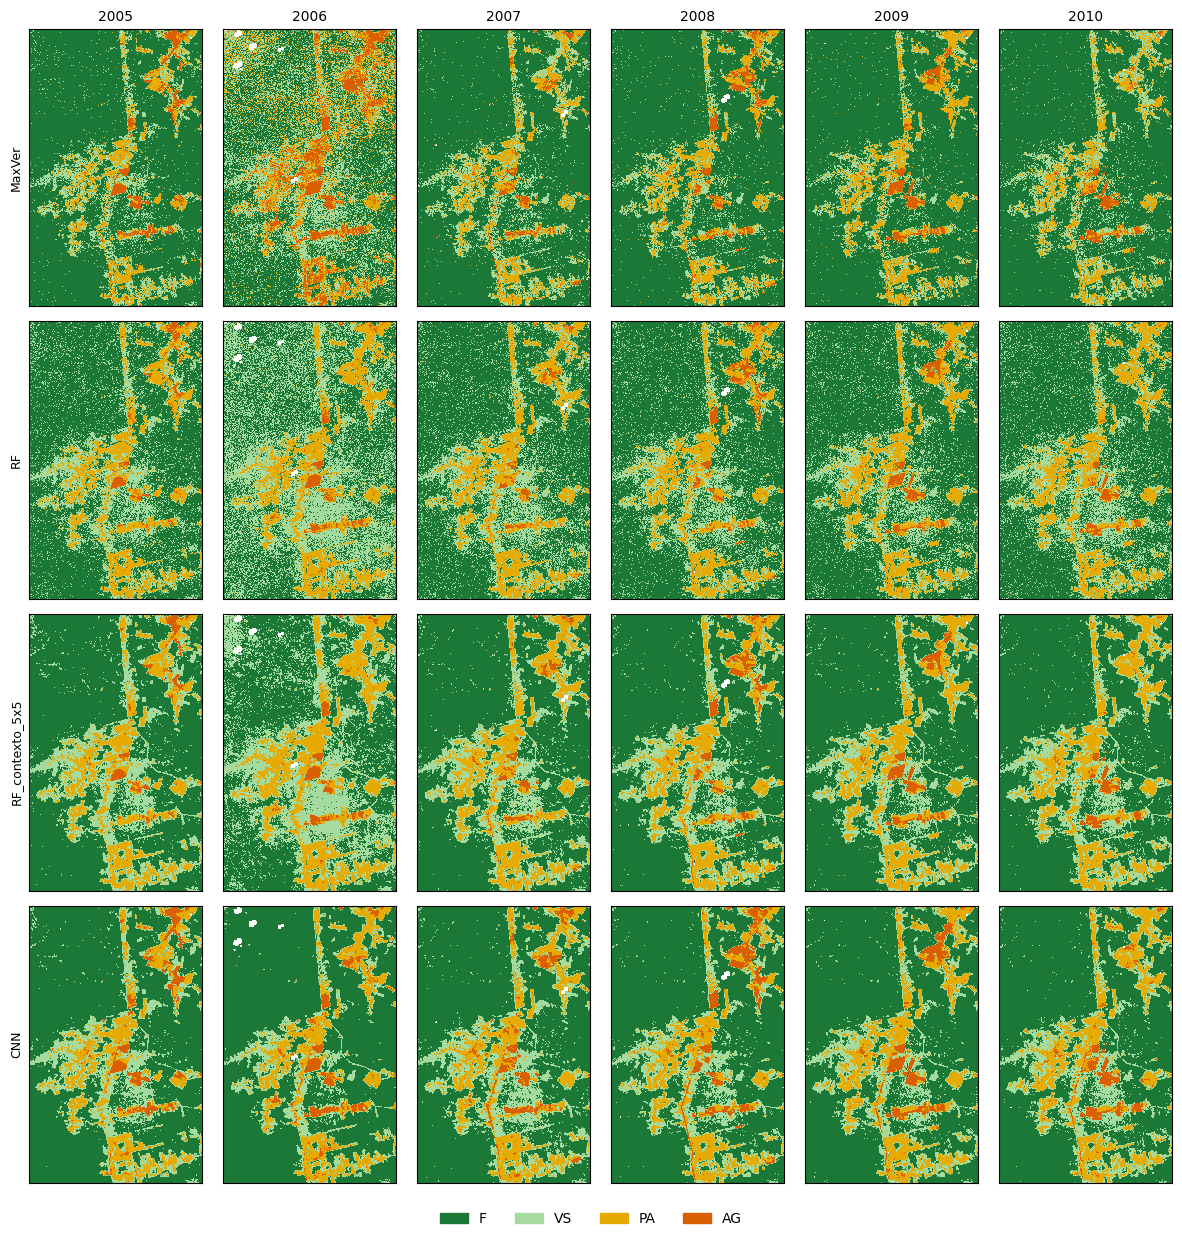

classe                   F    VS    PA   AG
classificador   ano                        
CNN             2005  66.8  17.7  12.0  3.5
                2006  71.2  13.1  12.7  3.0
                2007  65.0  18.8  13.1  3.1
                2008  67.6  16.4  11.9  4.2
                2009  67.3  16.2  13.0  3.5
                2010  66.4  17.5  13.5  2.7
MaxVer          2005  75.0  13.5   8.5  3.0
                2006  46.9  27.3  16.9  8.9
                2007  75.0  13.8   9.5  1.7
                2008  76.4  11.1   9.8  2.7
                2009  76.7  10.2  10.7  2.4
                2010  75.7  13.7   8.9  1.8
RF              2005  62.1  23.0  13.5  1.4
                2006  40.6  41.5  16.2  1.7
                2007  59.8  24.7  14.5  1.1
                2008  62.9  21.6  13.6  1.9
                2009  63.7  20.7  13.8  1.8
                2010  61.1  23.8  13.9  1.1
RF_contexto_5x5 2005  65.2  20.1  13.0  1.8
                2006  47.8  33.6  17.0  1.7
                2007  65.2  19.3  14.2  1.4
                2008  66.3  18.2  13.2  2.4
                2009  66.5  17.9  13.4  2.2
                2010  65.9  18.9  13.8  1.5
TerraClass      2008  72.9  10.0  13.6  3.5
                2010  70.6  10.7  15.6  3.0

In [7]:
CORES_CLASSES = {"F": "#1b7837", "VS": "#a6dba0", "PA": "#e6ab02", "AG": "#d95f02"}
cores = ListedColormap(["white"] + [CORES_CLASSES.get(s, "#999999") for s in SIGLAS])
nomes_mapas = list(mapas)
fig, eixos = plt.subplots(len(nomes_mapas), len(ANOS), figsize=(2.0 * len(ANOS), 3.1 * len(nomes_mapas)), squeeze=False)
for i, nome_saida in enumerate(nomes_mapas):
    for j, ano in enumerate(ANOS):
        ax = eixos[i, j]
        ax.imshow(mapas[nome_saida][ano], cmap=cores, vmin=-0.5, vmax=K + 0.5, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(str(ano), fontsize=10)
        if j == 0:
            ax.set_ylabel(nome_saida, fontsize=9)
fig.legend(handles=[Patch(color=CORES_CLASSES.get(s, "#999999"), label=s) for s in SIGLAS], loc="lower center", ncol=K, frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(os.path.join(PASTA_SAIDA, "mapas_por_data.png"), dpi=130)
plt.show()

linhas = []
for nome_saida in nomes_mapas:
    for ano in ANOS:
        v = mapas[nome_saida][ano]
        for k in range(K):
            linhas.append({"classificador": nome_saida, "ano": ano, "classe": SIGLAS[k], "pct": 100 * (v == k + 1).sum() / (v > 0).sum()})
for ano in ANOS:
    arq_ref = os.path.join(PASTA_REFERENCIA, f"referencia_{ano}.tif")
    if os.path.exists(arq_ref):
        with rasterio.open(arq_ref) as src:
            ref = src.read(1)
        na_legenda = np.isin(ref, CODIGOS) & valida_janela[ano]
        for k, cod in enumerate(CODIGOS):
            linhas.append({"classificador": "TerraClass", "ano": ano, "classe": SIGLAS[k],
                           "pct": 100 * ((ref == cod) & na_legenda).sum() / na_legenda.sum()})
tab_prop = pd.DataFrame(linhas).pivot_table(index=["classificador", "ano"], columns="classe", values="pct")[SIGLAS]
tab_prop.to_csv(os.path.join(PASTA_SAIDA, "proporcao_classes.csv"))
display(tab_prop.round(1))

## 7. Comparação rápida com o TerraClass (antes do CMAP)

Compara a classe mais provável de cada data com o TerraClass de 2008 e 2010 (`0c_referencia_terraclass`), em todos os pixels da referência dentro da legenda e com probabilidade. Como a comparação usa a **área inteira** (e não uma amostra), a acurácia global é a acurácia do mapa. Também é calculada sem os pixels de borda da referência (distância à borda ≥ 2).

É a classificação "data a data", sem a coerência temporal. A avaliação completa, com o CMAP, é feita no `4_cmap`; esta seção serve para verificar, antes disso, se os classificadores se comportam na área de estudo como nos folds do Pará.

In [8]:
linhas = []
for ano in ANOS:
    arq_ref = os.path.join(PASTA_REFERENCIA, f"referencia_{ano}.tif")
    if not os.path.exists(arq_ref):
        continue
    with rasterio.open(arq_ref) as src:
        ref = src.read(1)
    with rasterio.open(os.path.join(PASTA_REFERENCIA, f"dist_borda_{ano}.tif")) as src:
        dist_ref = src.read(1)
    for recorte in ("todos", "sem_borda"):
        sel = np.isin(ref, CODIGOS) & valida_janela[ano] & ((dist_ref >= 2) if recorte == "sem_borda" else True)
        y_ref = np.searchsorted(CODIGOS, ref[sel])
        for nome_saida in nomes_mapas:
            pred = mapas[nome_saida][ano][sel].astype(int) - 1
            cm = np.zeros((K, K), dtype=np.int64)
            np.add.at(cm, (y_ref, pred), 1)
            n_tot = cm.sum()
            oa = np.trace(cm) / n_tot
            pe = (cm.sum(axis=0) * cm.sum(axis=1)).sum() / n_tot ** 2
            n_ref, n_pred = cm.sum(axis=1), cm.sum(axis=0)
            ap = np.where(n_ref > 0, np.diag(cm) / np.maximum(n_ref, 1), np.nan)
            au = np.where(n_pred > 0, np.diag(cm) / np.maximum(n_pred, 1), np.nan)
            linha = {"ano": ano, "recorte": recorte, "classificador": nome_saida, "n": int(n_tot), "acuracia_global": oa,
                     "kappa": (oa - pe) / (1 - pe), "acuracia_balanceada": np.nanmean(ap[n_ref > 0])}
            for k in range(K):
                linha[f"AP_{SIGLAS[k]}"] = ap[k]
                linha[f"AU_{SIGLAS[k]}"] = au[k]
            linhas.append(linha)
            if recorte == "todos":
                pd.DataFrame(cm, index=[f"ref_{s}" for s in SIGLAS], columns=[f"prev_{s}" for s in SIGLAS]).to_csv(
                    os.path.join(PASTA_SAIDA, f"confusao_terraclass_{ano}_{nome_saida}.csv"))
tab_tc = pd.DataFrame(linhas)
if len(tab_tc):
    tab_tc.to_csv(os.path.join(PASTA_SAIDA, "comparacao_terraclass_antes_cmap.csv"), index=False)
    cols = ["acuracia_global", "kappa", "acuracia_balanceada"] + [f"AP_{s}" for s in SIGLAS] + [f"AU_{s}" for s in SIGLAS]
    for recorte in ("todos", "sem_borda"):
        print(f"\nRecorte: {recorte}")
        print(tab_tc[tab_tc.recorte == recorte].set_index(["ano", "classificador"])[cols].round(3).to_string())
else:
    print("Referência do 0c não encontrada: comparação não calculada")


Recorte: todos
                      acuracia_global  kappa  acuracia_balanceada   AP_F  AP_VS  AP_PA  AP_AG   AU_F  AU_VS  AU_PA  AU_AG
ano  classificador                                                                                                       
2008 MaxVer                     0.814  0.546                0.557  0.957  0.302  0.520  0.450  0.897  0.282  0.771  0.665
     RF                         0.776  0.546                0.628  0.831  0.620  0.708  0.353  0.943  0.289  0.760  0.727
     RF_contexto_5x5            0.839  0.658                0.687  0.900  0.734  0.702  0.412  0.967  0.411  0.780  0.684
     CNN                        0.848  0.672                0.720  0.913  0.690  0.680  0.597  0.963  0.430  0.824  0.579
2010 MaxVer                     0.784  0.503                0.521  0.951  0.289  0.440  0.404  0.885  0.228  0.777  0.716
     RF                         0.751  0.522                0.597  0.810  0.591  0.681  0.305  0.934  0.266  0.771  0.852
     RF_

## 8. Saídas e uso no CMAP

| Arquivo | Conteúdo |
|---|---|
| `<classificador>\logp_AAAA.tif` | log-probabilidade de cada classe (uma banda por classe, nome na descrição), média dos 5 modelos |
| `mascara_inferencia_AAAA.tif` | 1 = pixel sem probabilidade nesta data (comum a todos os classificadores) |
| `versao_classificadores.csv` | versão (bruta ou calibrada) usada em cada classificador e a NLL que a justificou |
| `temperaturas.csv`, `conferencia_teste.csv` | temperatura de cada fold e conferência com os notebooks anteriores |
| `conferencia_dominio.csv` | medianas de cada classe na área de estudo × treino |
| `mapas_por_data.png`, `proporcao_classes.csv` | classe mais provável por data e proporções, antes do CMAP |
| `comparacao_terraclass_antes_cmap.csv`, `confusao_terraclass_*.csv` | comparação com o TerraClass 2008 e 2010, antes do CMAP |

No `4_cmap`, os nomes das classes nas matrizes de transição precisam ser as mesmas siglas das bandas (F, VS, PA, AG), e os códigos (`class_codes`) devem ser os da legenda: F = 1, VS = 2, PA = 3, AG = 4. Use `mask_mode="ignore"` com as máscaras de inferência: a data sem probabilidade não informa a trajetória daquele pixel.

In [9]:
total = 0
for raiz, _, arquivos in os.walk(PASTA_SAIDA):
    total += sum(os.path.getsize(os.path.join(raiz, a)) for a in arquivos)
print(f"Saídas em {PASTA_SAIDA}: {total / 1e6:.0f} MB")

Saídas em C:\cmap_ftl\terraclass\resultados\3_inferencia\6bandas_patch5: 269 MB
